# 06 · Descarga del Pitt Image Ads Dataset (anuncios atípicos)

Descarga las imágenes y los textos asociados del subconjunto de anuncios atípicos publicado en
<https://people.cs.pitt.edu/~nhonarvar/data_analysis/interface.html> (Hussain et al., CVPR 2017).

La página carga dos archivos JSON:

- `category_topic_sentiment.json`: **categoría atípica → tema → sentimiento → lista de imágenes**.
- `final_Annotation_QA.json`: textos por imagen, con las respuestas **Q&A** (*"I should… because…"*) y las descripciones del elemento atípico (**Atypical_Annot**).

Las imágenes están en `https://people.cs.pitt.edu/~mzhang/image_ads/<carpeta>/<id>.jpg`, donde la carpeta es el último dígito del ID, o `10` si el ID es 170000 o mayor.

**Salida:** en Colab, `MyDrive/publicity_analysis/pitt/` de Google Drive (la misma carpeta base que usa `01_entrenamiento`); en local, `./pitt/`.

| Archivo | Contenido |
|---|---|
| `images/<id>.jpg` | imágenes |
| `metadata.csv` | una fila por imagen (categorías, temas, sentimientos, Q&A, descripciones atípicas) |
| `metadata_largo.csv` | una fila por combinación imagen–categoría–tema–sentimiento |
| `raw/*.json` | JSON originales |

Solo usa la biblioteca estándar de Python. Si la descarga se interrumpe, al volver a ejecutar se saltan las imágenes que ya existen.

## 1. Configuración

In [1]:
import csv
import html
import json
import re
import time
import urllib.request
from concurrent.futures import ThreadPoolExecutor, as_completed
from pathlib import Path

import pandas as pd

# En Colab se guarda en Google Drive, en la misma carpeta que usa 01_entrenamiento
# (/content se borra al cortarse la sesión). En local se usa ./pitt.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DIR = Path('/content/drive/MyDrive/publicity_analysis')
    OUT = DRIVE_DIR / 'pitt'
except ImportError:
    OUT = Path('pitt')
WORKERS = 6             # descargas en paralelo
PAUSA = 0.1             # segundos entre descargas por hilo
LIMIT = None            # p. ej. 20 para probar; None = todas

BASE_META = "https://people.cs.pitt.edu/~nhonarvar/data_analysis/"
BASE_IMG = "https://people.cs.pitt.edu/~mzhang/image_ads/"
JSON_CTS = "category_topic_sentiment.json"
JSON_QA = "final_Annotation_QA.json"
SEP = " || "
UA = {"User-Agent": "Mozilla/5.0 (research dataset downloader)"}

RAW_DIR, IMG_DIR = OUT / "raw", OUT / "images"
RAW_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)
print("Salida en:", OUT.resolve())

Mounted at /content/drive
Salida en: /content/drive/MyDrive/publicity_analysis/pitt


## 2. Funciones auxiliares

In [2]:
def fetch(url, timeout=30, retries=3):
    for k in range(retries):
        try:
            req = urllib.request.Request(url, headers=UA)
            with urllib.request.urlopen(req, timeout=timeout) as r:
                return r.read()
        except Exception:
            if k == retries - 1:
                raise
            time.sleep(1.5 * (k + 1))


def id2url(image_id):
    """Misma regla que la función id2url() de la página."""
    stem = image_id.split(".")[0]
    folder = "10" if int(stem) >= 170000 else stem[-1]
    return f"{BASE_IMG}{folder}/{image_id}"


def limpiar_html(s):
    return html.unescape(re.sub(r"<[^>]+>", "", s)).strip()


def cargar_json(nombre):
    path = RAW_DIR / nombre
    if not path.exists():
        path.write_bytes(fetch(BASE_META + nombre))
    return json.loads(path.read_text(encoding="utf-8"))

## 3. Metadatos y textos

In [3]:
cts = cargar_json(JSON_CTS)
qa = cargar_json(JSON_QA)

largo, por_img = [], {}
for cat, temas in cts.items():
    for tema, sents in temas.items():
        for sent, ids in sents.items():
            for i in ids:
                largo.append({"image": i, "category": cat, "topic": tema, "sentiment": sent})
                d = por_img.setdefault(i, {"category": set(), "topic": set(), "sentiment": set()})
                d["category"].add(cat); d["topic"].add(tema); d["sentiment"].add(sent)

# imágenes con texto que no aparecen en los filtros de la página
for i in qa:
    por_img.setdefault(i, {"category": set(), "topic": set(), "sentiment": set()})

filas = []
for i in sorted(por_img, key=lambda x: int(x.split(".")[0])):
    a = qa.get(i, {})
    qas = [limpiar_html(x) for x in a.get("QA", [])]
    aty = [limpiar_html(x) for x in a.get("Atypical_Annot", [])]
    d = por_img[i]
    filas.append({
        "image": i,
        "url": id2url(i),
        "categories": SEP.join(sorted(d["category"])),
        "topics": SEP.join(sorted(d["topic"])),
        "sentiments": SEP.join(sorted(d["sentiment"])),
        "n_qa": len(qas),
        "qa": SEP.join(qas),
        "n_atypical": len(aty),
        "atypical": SEP.join(aty),
        "has_text": int(bool(qas or aty)),
    })

meta = pd.DataFrame(filas)
meta_largo = pd.DataFrame(largo)
if LIMIT:
    meta = meta.head(LIMIT)
    meta_largo = meta_largo[meta_largo["image"].isin(meta["image"])]

meta.to_csv(OUT / "metadata.csv", index=False)
meta_largo.to_csv(OUT / "metadata_largo.csv", index=False)
print(f"{len(meta)} imágenes, {meta['has_text'].sum()} con texto, {len(meta_largo)} filas en formato largo")
meta.head()

2411 imágenes, 2060 con texto, 21396 filas en formato largo


,image,url,categories,topics,sentiments,n_qa,qa,n_atypical,atypical,has_text
0,60.jpg,https://people.cs.pitt.edu/~mzhang/image_ads/0...,category9,electronics || media,active || creative || educated || inspired || ...,0,,0,,0
1,160.jpg,https://people.cs.pitt.edu/~mzhang/image_ads/0...,category9,electronics || phone_tv_internet_providers,cheerful || creative || eager || persuaded || ...,5,I should buy these phone products Because I wi...,1,Object Inside Object: Objects which are inside...,1
2,172.jpg,https://people.cs.pitt.edu/~mzhang/image_ads/2...,Solid Deformed Object,electronics || phone_tv_internet_providers,amused || cheerful || confident || creative,3,I should call AT&T Because they will give me a...,1,Solid Deformed Object: The objects that have b...,1
3,201.jpg,https://people.cs.pitt.edu/~mzhang/image_ads/1...,Texture Replacement 1,electronics,amazed || confident || creative || inspired ||...,3,I should buy this phone Because it has a cool ...,1,Texture Replacement 1: The object which has a ...,1
4,202.jpg,https://people.cs.pitt.edu/~mzhang/image_ads/2...,Object Replacement || Texture Replacement 2,phone_tv_internet_providers,active,3,I should learn more about AT&T Because they sp...,3,Texture Replacement 2: The object which has a ...,1


In [4]:
# Resumen por categoría atípica
meta_largo.groupby("category")["image"].nunique().sort_values(ascending=False).rename("n_imagenes")

,n_imagenes
category,
Object Replacement,769
category9,643
Texture Replacement 1,434
Combination of Parts,351
Texture Replacement 2,316
Solid Deformed Object,245
Object Inside Object,237
Liquid Deformed Object,236
Object with Missing Part,139


## 4. Descarga de imágenes

In [5]:
def descargar_una(image_id):
    dest = IMG_DIR / image_id
    if dest.exists() and dest.stat().st_size > 0:
        return image_id, "existe"
    try:
        data = fetch(id2url(image_id))
        tmp = dest.with_suffix(".part")
        tmp.write_bytes(data)
        tmp.rename(dest)
        time.sleep(PAUSA)
        return image_id, "ok"
    except Exception as e:
        return image_id, f"error: {e}"


ids = meta["image"].tolist()
print(f"Descargando {len(ids)} imágenes con {WORKERS} hilos...")
t0 = time.time()
errores, cont = [], {"ok": 0, "existe": 0}
with ThreadPoolExecutor(max_workers=WORKERS) as ex:
    futs = [ex.submit(descargar_una, i) for i in ids]
    for k, fu in enumerate(as_completed(futs), 1):
        i, estado = fu.result()
        if estado.startswith("error"):
            errores.append((i, estado))
        else:
            cont[estado] += 1
        if k % 100 == 0 or k == len(ids):
            print(f"  {k}/{len(ids)}  ({time.time() - t0:.0f}s)", flush=True)

print(f"Listo: {cont['ok']} nuevas, {cont['existe']} ya existían, {len(errores)} errores.")
if errores:
    pd.DataFrame(errores, columns=["image", "error"]).to_csv(OUT / "errores.csv", index=False)
    print(f"Ver {OUT / 'errores.csv'} (vuelve a ejecutar esta celda para reintentar).")

Descargando 2411 imágenes con 6 hilos...
  100/2411  (10s)
  200/2411  (21s)
  300/2411  (31s)
  400/2411  (42s)
  500/2411  (53s)
  600/2411  (63s)
  700/2411  (92s)
  800/2411  (102s)
  900/2411  (113s)
  1000/2411  (123s)
  1100/2411  (135s)
  1200/2411  (145s)
  1300/2411  (157s)
  1400/2411  (168s)
  1500/2411  (179s)
  1600/2411  (190s)
  1700/2411  (201s)
  1800/2411  (213s)
  1900/2411  (223s)
  2000/2411  (233s)
  2100/2411  (249s)
  2200/2411  (260s)
  2300/2411  (271s)
  2400/2411  (283s)
  2411/2411  (284s)
Listo: 2411 nuevas, 0 ya existían, 0 errores.


## 5. Verificación: algunas imágenes con su texto

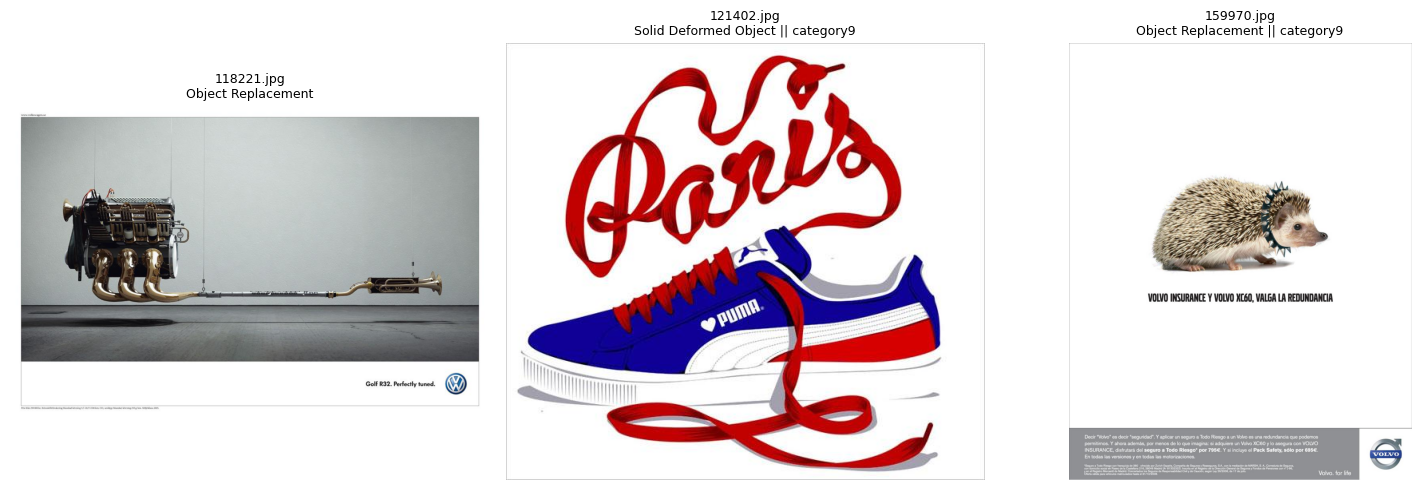


== 118221.jpg | temas: cars | sentimientos: active || creative || fashionable
  QA : I should buy Volkswagen Because the car is perfectly tuned,like an instrument.
  QA : I should buy a BMW Golf R32 Because it is perfectly tuned.
  QA : I should buy volkswagen because its powerful engine
  ATY: Object with Missing Part: The objects which have missing parts are car
  ATY: Object Replacement: The object which is placed in the context of another object is trumpets and the object which is replaced by another object (expected object) muffler

== 121402.jpg | temas: clothing || sports | sentimientos: active || creative || fashionable || persuaded
  QA : I should wear Puma Because it is classy
  QA : I should buy these puma shoes Because they are made from Paris flag
  QA : I should wear Puma shoes Because they are popular in Paris.
  ATY: Solid Deformed Object: The objects that have been transformed are show lace and the transformations are spells "Paris"

== 159970.jpg | temas: cars || env

In [6]:
import matplotlib.pyplot as plt
from PIL import Image

muestra = meta[meta["has_text"] == 1].sample(3, random_state=0)
fig, axes = plt.subplots(1, len(muestra), figsize=(15, 5))
for ax, (_, r) in zip(axes, muestra.iterrows()):
    p = IMG_DIR / r["image"]
    if p.exists():
        ax.imshow(Image.open(p))
    ax.set_title(f"{r['image']}\n{r['categories']}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

for _, r in muestra.iterrows():
    print(f"\n== {r['image']} | temas: {r['topics']} | sentimientos: {r['sentiments']}")
    for q in r["qa"].split(SEP):
        print("  QA :", q)
    for a in r["atypical"].split(SEP):
        print("  ATY:", a)